# 01 — Analyse exploratoire météo : Sidi Bouzid 🇹🇳 × Niigata 🇯🇵

**Objectif** : comprendre les données météo journalières (2015–2025) avant d'entraîner le modèle d'ET0 : qualité, distributions, saisonnalité de l'ET0, bilan hydrique, corrélations, autocorrélation, et premières références (persistance, Hargreaves). **Aucun modèle n'est entraîné ici.**

| | |
|---|---|
| **Entrées** | `data/processed/weather_daily_tunisia.parquet`, `weather_daily_japan.parquet` (produits par `python -m ingest.run_all`) |
| **Sorties** | figures et métriques dans MLflow (expérience `01_eda_weather`), `models/artifacts/eda_weather_summary.json` |
| **Durée** | < 1 min |

Source : Open-Meteo (réanalyse ERA5), l'ET0 est l'évapotranspiration de référence FAO-56 Penman-Monteith calculée par Open-Meteo.

## 1. Imports, chemins et MLflow

In [1]:
import json
import logging
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns

EXPERIMENT = "01_eda_weather"
SEED = 42
np.random.seed(SEED)

# Racine du projet : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "aquamind_core").is_dir())
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
ARTIFACTS = ROOT / "models" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
logging.getLogger("mlflow").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# MLflow : file store local mlruns/ à la racine (équivalent de "file:../mlruns" depuis notebooks/)
mlflow.set_tracking_uri((ROOT / "mlruns").as_uri())
mlflow.set_experiment(EXPERIMENT)
mlflow.end_run()  # ferme un run resté ouvert par une exécution précédente interrompue
run = mlflow.start_run(run_name=f"{EXPERIMENT}-{time.strftime('%Y%m%d-%H%M%S')}")
T0 = time.perf_counter()
print("Racine :", ROOT)
print("MLflow :", mlflow.get_tracking_uri(), "| run", run.info.run_id)

Racine : c:\Users\ghodh\aquamind
MLflow : file:///c:/Users/ghodh/aquamind/mlruns | run a1d8c01dcd3548dda8543283e7898189


## 2. Chargement

In [2]:
from aquamind_core.config import get_settings

settings = get_settings()
SITES = {
    "tunisia": {"label": "Sidi Bouzid (TN)", "lat": settings.farm_lat, "color": "#d9822b"},
    "japan": {"label": "Niigata (JP)", "lat": settings.japan_lat, "color": "#2b7bb9"},
}
PALETTE = {v["label"]: v["color"] for v in SITES.values()}
VARS = {
    "et0_fao_evapotranspiration": "ET0 FAO-56 (mm/j)",
    "temperature_2m_max": "Tmax (°C)",
    "temperature_2m_min": "Tmin (°C)",
    "temperature_2m_mean": "Tmoy (°C)",
    "precipitation_sum": "Pluie (mm/j)",
    "shortwave_radiation_sum": "Rayonnement (MJ/m²/j)",
    "wind_speed_10m_max": "Vent max (km/h)",
    "relative_humidity_2m_mean": "Humidité relative (%)",
}

df = pd.concat([pd.read_parquet(PROCESSED / f"weather_daily_{s}.parquet") for s in SITES]).reset_index()
missing_vars = [v for v in VARS if v not in df.columns]
assert not missing_vars, f"Variables absentes (relancer python -m ingest.run_all) : {missing_vars}"
df["site_label"] = df["site"].map({k: v["label"] for k, v in SITES.items()})
df["year"], df["month"], df["doy"] = df["date"].dt.year, df["date"].dt.month, df["date"].dt.dayofyear
print(df.shape, "|", df["date"].min().date(), "→", df["date"].max().date())
df.head()

(8036, 14) | 2015-01-01 → 2025-12-31


,date,site,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,shortwave_radiation_sum,wind_speed_10m_max,relative_humidity_2m_mean,et0_fao_evapotranspiration,site_label,year,month,doy
0,2015-01-01,tunisia,7.8,-0.8,3.3,2.4,7.96,31.2,77,1.28,Sidi Bouzid (TN),2015,1,1
1,2015-01-02,tunisia,10.6,3.9,6.7,0.0,8.00,20.3,65,1.58,Sidi Bouzid (TN),2015,1,2
2,2015-01-03,tunisia,15.8,2.2,8.0,0.0,11.42,9.7,72,1.75,Sidi Bouzid (TN),2015,1,3
3,2015-01-04,tunisia,19.6,4.0,10.8,0.0,11.64,13.5,47,2.76,Sidi Bouzid (TN),2015,1,4
4,2015-01-05,tunisia,15.5,5.5,10.7,0.0,10.85,19.2,62,2.24,Sidi Bouzid (TN),2015,1,5


## 3. Qualité des données
Attendu : 4018 jours par site, aucun doublon, 0 % de valeurs manquantes.

In [3]:
coverage = df.groupby("site")["date"].agg(jours="count", debut="min", fin="max")
coverage["jours_attendus"] = (coverage["fin"] - coverage["debut"]).dt.days + 1
coverage["doublons"] = df.duplicated(["site", "date"]).groupby(df["site"]).sum()
display(coverage)
missing_pct = (df.groupby("site")[list(VARS)].agg(lambda s: s.isna().mean() * 100).T.round(2))
display(missing_pct.rename(columns=lambda c: f"% manquants {c}"))
df.groupby("site_label")[list(VARS)].describe().T.round(2)

,jours,debut,fin,jours_attendus,doublons
site,,,,,
japan,4018,2015-01-01,2025-12-31,4018,0
tunisia,4018,2015-01-01,2025-12-31,4018,0


site,% manquants japan,% manquants tunisia
et0_fao_evapotranspiration,0.0,0.0
temperature_2m_max,0.0,0.0
temperature_2m_min,0.0,0.0
temperature_2m_mean,0.0,0.0
precipitation_sum,0.0,0.0
shortwave_radiation_sum,0.0,0.0
wind_speed_10m_max,0.0,0.0
relative_humidity_2m_mean,0.0,0.0


site_label                        Niigata (JP)  Sidi Bouzid (TN)
et0_fao_evapotranspiration count       4018.00           4018.00
                           mean           2.70              4.48
                           std            1.41              2.04
                           min            0.36              0.37
                           25%            1.54              2.71
...                                        ...               ...
relative_humidity_2m_mean  min           46.00             10.00
                           25%           68.00             43.00
                           50%           75.00             53.00
                           75%           81.00             65.00
                           max           94.00             98.00

[64 rows x 2 columns]

## 4. Distributions

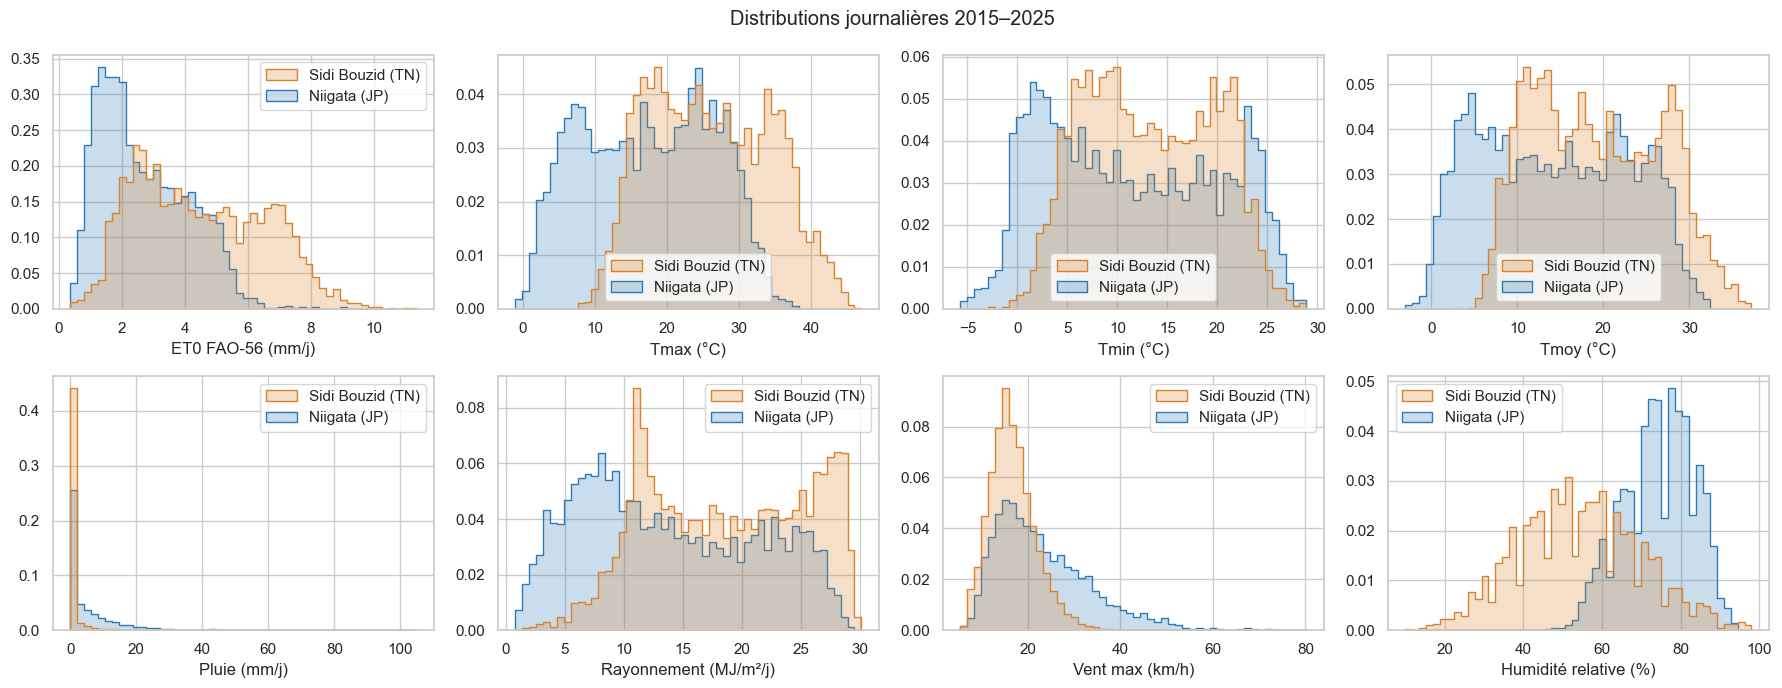

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, (col, label) in zip(axes.flat, VARS.items()):
    sns.histplot(data=df, x=col, hue="site_label", palette=PALETTE, element="step",
                 stat="density", common_norm=False, bins=50, ax=ax)
    ax.set_xlabel(label)
    ax.set_ylabel("")
    if ax.get_legend() is not None:
        ax.get_legend().set_title("")
fig.suptitle("Distributions journalières 2015–2025")
fig.tight_layout()
mlflow.log_figure(fig, "fig_distributions.png")
plt.show()

## 5. Saisonnalité de l'ET0 et de la pluie

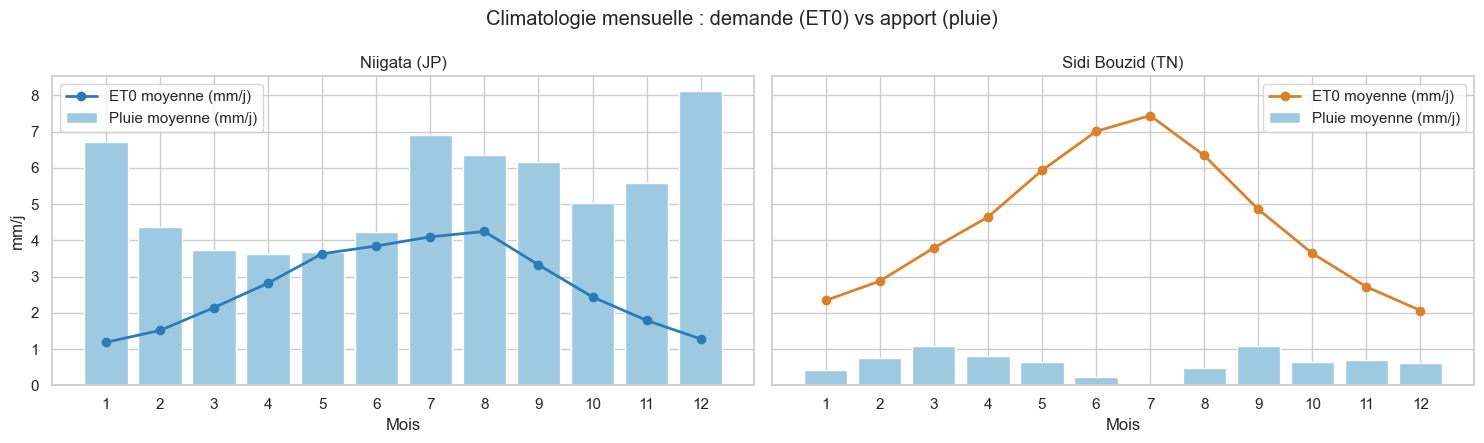

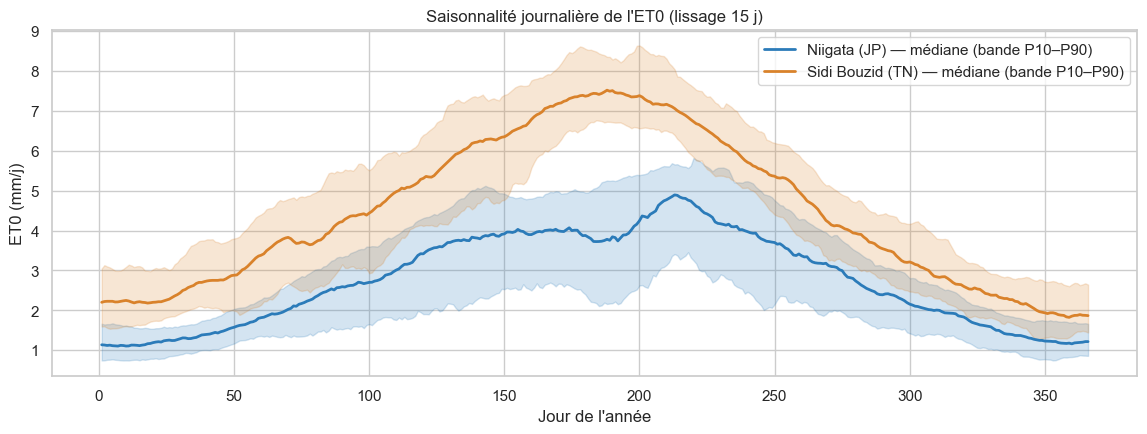

In [5]:
clim = (df.groupby(["site_label", "month"])
          .agg(et0=("et0_fao_evapotranspiration", "mean"), pluie=("precipitation_sum", "mean"))
          .reset_index())
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (label, g) in zip(axes, clim.groupby("site_label")):
    ax.bar(g["month"], g["pluie"], color="#9ecae1", label="Pluie moyenne (mm/j)")
    ax.plot(g["month"], g["et0"], "o-", color=PALETTE[label], lw=2, label="ET0 moyenne (mm/j)")
    ax.set_title(label)
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Mois")
    ax.legend()
axes[0].set_ylabel("mm/j")
fig.suptitle("Climatologie mensuelle : demande (ET0) vs apport (pluie)")
fig.tight_layout()
mlflow.log_figure(fig, "fig_saisonnalite_mensuelle.png")
plt.show()

fig, ax = plt.subplots(figsize=(14, 4.5))
for label, g in df.groupby("site_label"):
    q = g.groupby("doy")["et0_fao_evapotranspiration"].quantile([0.1, 0.5, 0.9]).unstack()
    q = q.rolling(15, center=True, min_periods=1).mean()
    ax.fill_between(q.index, q[0.1], q[0.9], color=PALETTE[label], alpha=0.2)
    ax.plot(q.index, q[0.5], color=PALETTE[label], lw=2, label=f"{label} — médiane (bande P10–P90)")
ax.set_xlabel("Jour de l'année")
ax.set_ylabel("ET0 (mm/j)")
ax.set_title("Saisonnalité journalière de l'ET0 (lissage 15 j)")
ax.legend()
mlflow.log_figure(fig, "fig_saisonnalite_journaliere.png")
plt.show()

## 6. Bilan hydrique annuel (ET0 − pluie)
Le déficit annuel indique le besoin structurel d'irrigation.

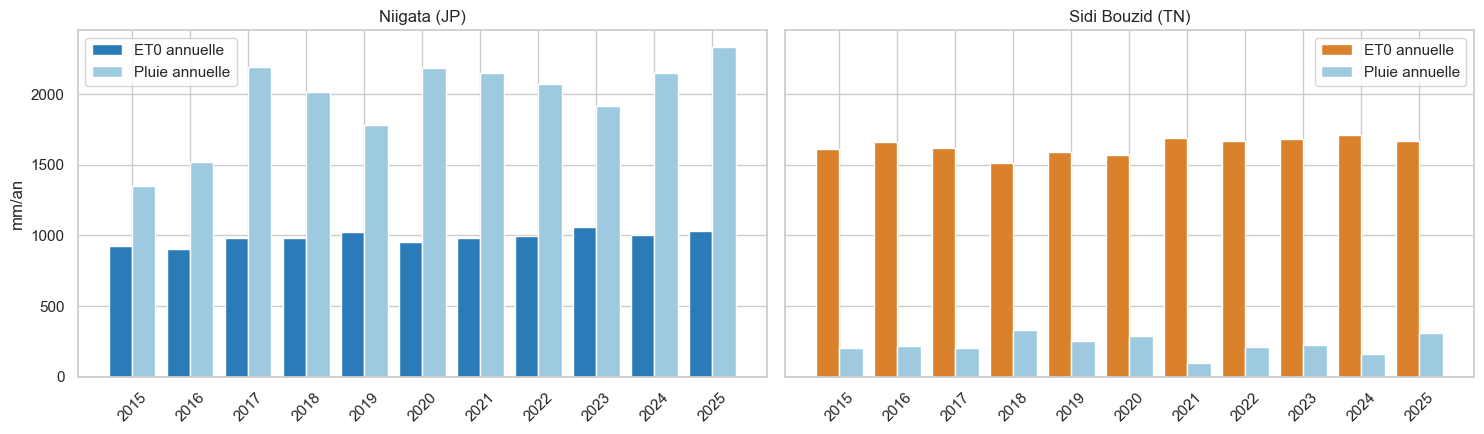

,et0,pluie,deficit
site_label,,,
Niigata (JP),986.0,1969.0,-984.0
Sidi Bouzid (TN),1636.0,228.0,1408.0


In [6]:
annual = (df.groupby(["site_label", "year"])
            .agg(et0=("et0_fao_evapotranspiration", "sum"), pluie=("precipitation_sum", "sum"))
            .reset_index())
annual["deficit"] = annual["et0"] - annual["pluie"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (label, g) in zip(axes, annual.groupby("site_label")):
    x = np.arange(len(g))
    ax.bar(x - 0.2, g["et0"], 0.4, color=PALETTE[label], label="ET0 annuelle")
    ax.bar(x + 0.2, g["pluie"], 0.4, color="#9ecae1", label="Pluie annuelle")
    ax.set_xticks(x, g["year"], rotation=45)
    ax.set_title(label)
    ax.legend()
axes[0].set_ylabel("mm/an")
fig.tight_layout()
mlflow.log_figure(fig, "fig_bilan_annuel.png")
plt.show()
annual_mean = annual.groupby("site_label")[["et0", "pluie", "deficit"]].mean().round(0)
annual_mean

## 7. Corrélations (Spearman)

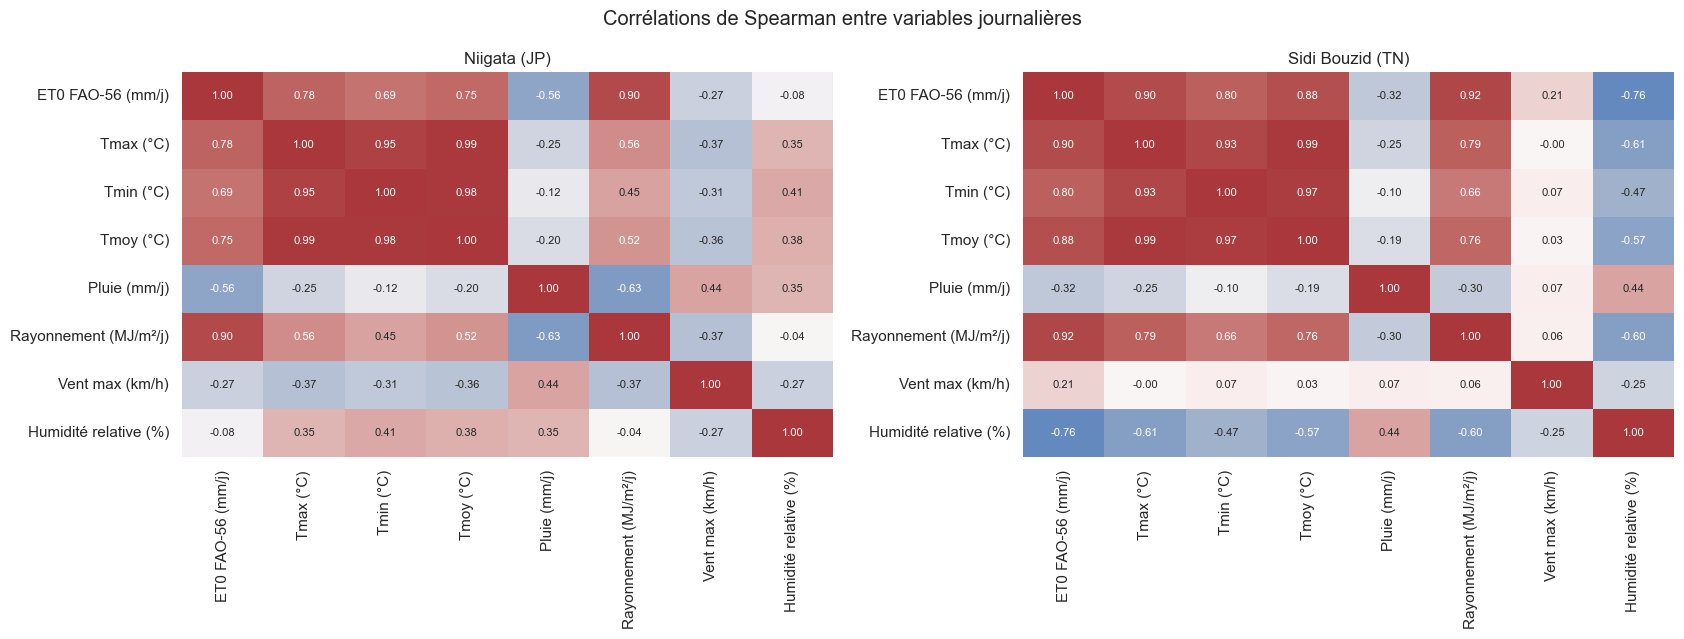

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, (label, g) in zip(axes, df.groupby("site_label")):
    corr = g[list(VARS)].rename(columns=VARS).corr(method="spearman")
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, cbar=False,
                annot_kws={"size": 8}, ax=ax)
    ax.set_title(label)
fig.suptitle("Corrélations de Spearman entre variables journalières")
fig.tight_layout()
mlflow.log_figure(fig, "fig_correlations.png")
plt.show()

## 8. Autocorrélation de l'ET0
Une forte autocorrélation aux décalages 1–7 justifie les *lags* utilisés dans le notebook 02.

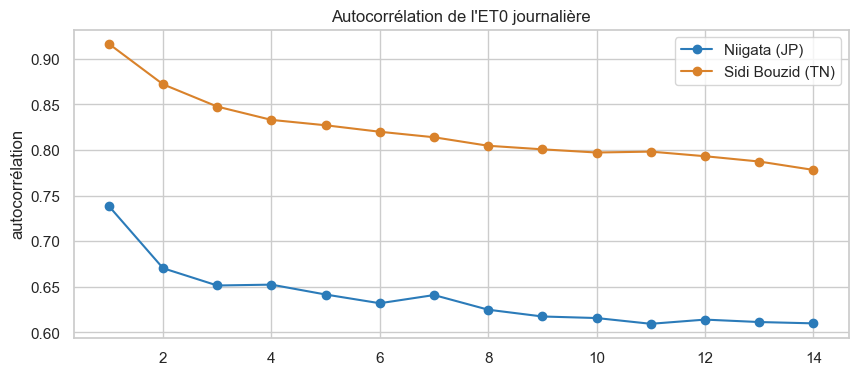

décalage (jours),1,2,3,4,5,6,7,8,9,10,11,12,13,14
Niigata (JP),0.739,0.670,0.651,0.652,0.642,0.632,0.641,0.625,0.617,0.616,0.609,0.614,0.611,0.610
Sidi Bouzid (TN),0.916,0.872,0.848,0.833,0.827,0.820,0.814,0.805,0.801,0.797,0.798,0.793,0.787,0.778


In [8]:
acf = {label: [g.sort_values("date")["et0_fao_evapotranspiration"].autocorr(lag) for lag in range(1, 15)]
       for label, g in df.groupby("site_label")}
acf_df = pd.DataFrame(acf, index=pd.RangeIndex(1, 15, name="décalage (jours)"))
fig, ax = plt.subplots(figsize=(10, 4))
for label in acf_df.columns:
    ax.plot(acf_df.index, acf_df[label], "o-", color=PALETTE[label], label=label)
ax.set_ylabel("autocorrélation")
ax.set_title("Autocorrélation de l'ET0 journalière")
ax.legend()
mlflow.log_figure(fig, "fig_autocorrelation.png")
plt.show()
acf_df.round(3).T

## 9. Références simples : persistance et Hargreaves

- **Persistance** : ET0(J+1) = ET0(J). C'est la référence à battre pour le modèle LightGBM.
- **Hargreaves-Samani** (FAO-56, éq. 52) : ET0 = 0,0023 × 0,408 × Ra × (Tmoy + 17,8) × √(Tmax − Tmin). Ra est le rayonnement extraterrestre (FAO-56, éq. 21). Cette formule ne demande que les températures : elle sert de **secours** au backend.

,ET0 moyenne (mm/j),MAE persistance J+1 (mm/j),MAE Hargreaves (mm/j),biais Hargreaves (mm/j)
site,,,,
japan,2.698,0.730,0.680,-0.408
tunisia,4.479,0.611,0.644,-0.461


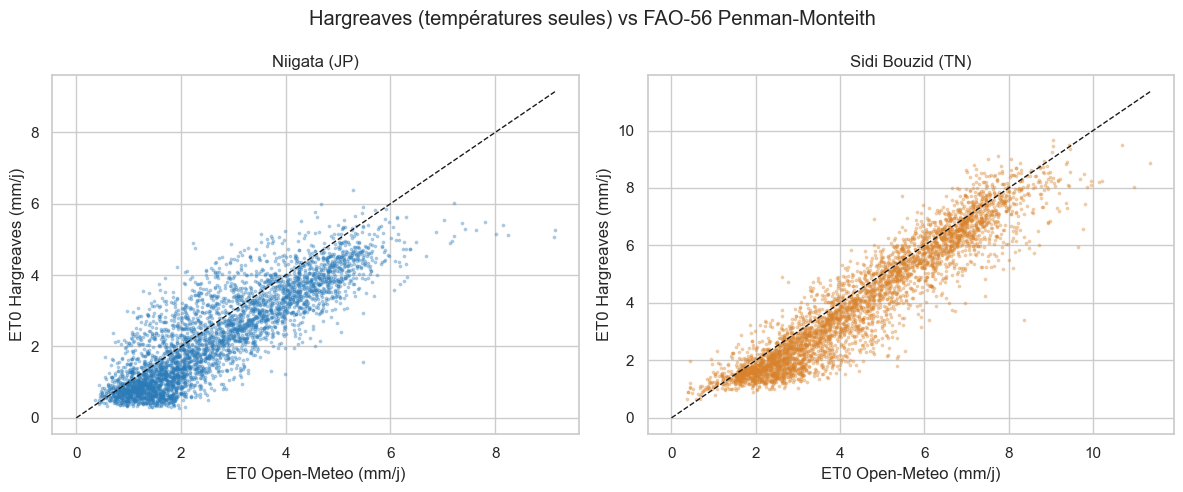

In [9]:
def extraterrestrial_radiation(lat_deg: float, doy: np.ndarray) -> np.ndarray:
    """Rayonnement extraterrestre Ra (MJ/m²/j), FAO-56 éq. 21."""
    phi = np.radians(lat_deg)
    dr = 1 + 0.033 * np.cos(2 * np.pi * doy / 365)
    delta = 0.409 * np.sin(2 * np.pi * doy / 365 - 1.39)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1, 1))
    return 24 * 60 / np.pi * 0.0820 * dr * (ws * np.sin(phi) * np.sin(delta)
                                            + np.cos(phi) * np.cos(delta) * np.sin(ws))


def hargreaves_et0(tmax, tmin, ra):
    """ET0 de Hargreaves-Samani (mm/j), FAO-56 éq. 52."""
    tmean = (tmax + tmin) / 2
    return 0.0023 * 0.408 * ra * (tmean + 17.8) * np.sqrt(np.clip(tmax - tmin, 0, None))


rows = []
df["et0_hargreaves"] = np.nan
for site, g in df.groupby("site"):
    g = g.sort_values("date")
    et0 = g["et0_fao_evapotranspiration"]
    ra = extraterrestrial_radiation(SITES[site]["lat"], g["doy"].to_numpy())
    hs = hargreaves_et0(g["temperature_2m_max"].to_numpy(), g["temperature_2m_min"].to_numpy(), ra)
    df.loc[g.index, "et0_hargreaves"] = hs
    pers = et0.shift(1)
    ok = pers.notna()
    rows.append({
        "site": site,
        "ET0 moyenne (mm/j)": et0.mean(),
        "MAE persistance J+1 (mm/j)": (et0[ok] - pers[ok]).abs().mean(),
        "MAE Hargreaves (mm/j)": np.abs(hs - et0.to_numpy()).mean(),
        "biais Hargreaves (mm/j)": (hs - et0.to_numpy()).mean(),
    })
baselines = pd.DataFrame(rows).set_index("site").round(3)
display(baselines)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (label, g) in zip(axes, df.groupby("site_label")):
    ax.scatter(g["et0_fao_evapotranspiration"], g["et0_hargreaves"], s=3, alpha=0.3, color=PALETTE[label])
    lim = [0, max(g["et0_fao_evapotranspiration"].max(), g["et0_hargreaves"].max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlabel("ET0 Open-Meteo (mm/j)")
    ax.set_ylabel("ET0 Hargreaves (mm/j)")
    ax.set_title(label)
fig.suptitle("Hargreaves (températures seules) vs FAO-56 Penman-Monteith")
fig.tight_layout()
mlflow.log_figure(fig, "fig_hargreaves.png")
plt.show()

## 10. Comparaison Tunisie / Japon et export

In [10]:
summary = {}
for site, meta in SITES.items():
    g = df[df["site"] == site]
    a = annual[annual["site_label"] == meta["label"]]
    summary[site] = {
        "label": meta["label"],
        "et0_mean_mm_d": round(float(g["et0_fao_evapotranspiration"].mean()), 3),
        "et0_p95_mm_d": round(float(g["et0_fao_evapotranspiration"].quantile(0.95)), 3),
        "et0_annual_mm": round(float(a["et0"].mean()), 1),
        "rain_annual_mm": round(float(a["pluie"].mean()), 1),
        "deficit_annual_mm": round(float(a["deficit"].mean()), 1),
        "tmax_p95_c": round(float(g["temperature_2m_max"].quantile(0.95)), 1),
        "rh_mean_pct": round(float(g["relative_humidity_2m_mean"].mean()), 1),
        "et0_autocorr_lag1": round(float(acf_df.loc[1, meta["label"]]), 3),
        "mae_persistence_mm_d": round(float(baselines.loc[site, "MAE persistance J+1 (mm/j)"]), 3),
        "mae_hargreaves_mm_d": round(float(baselines.loc[site, "MAE Hargreaves (mm/j)"]), 3),
        "n_days": int(len(g)),
    }
comparison = pd.DataFrame(summary).T.drop(columns="label")
comparison.index = [SITES[s]["label"] for s in comparison.index]
display(comparison)

for site, vals in summary.items():
    mlflow.log_metrics({f"{site}_{k}": v for k, v in vals.items() if isinstance(v, (int, float))})
export = {"source": "Open-Meteo archive (ERA5), 2015-01-01 → 2025-12-31", "sites": summary}
with open(ARTIFACTS / "eda_weather_summary.json", "w", encoding="utf-8") as f:
    json.dump(export, f, ensure_ascii=False, indent=2)
mlflow.log_dict(export, "eda_weather_summary.json")
print("Écrit", ARTIFACTS / "eda_weather_summary.json")

,et0_mean_mm_d,et0_p95_mm_d,et0_annual_mm,rain_annual_mm,deficit_annual_mm,tmax_p95_c,rh_mean_pct,et0_autocorr_lag1,mae_persistence_mm_d,mae_hargreaves_mm_d,n_days
Sidi Bouzid (TN),4.479,7.821,1636.0,228.5,1407.6,39.6,54.2,0.916,0.611,0.644,4018
Niigata (JP),2.698,5.17,985.6,1969.1,-983.6,30.9,74.4,0.739,0.73,0.68,4018


Écrit c:\Users\ghodh\aquamind\models\artifacts\eda_weather_summary.json


## Résumé des métriques

In [11]:
print(f"=== 01_eda_weather — exécuté en {time.perf_counter() - T0:.1f} s ===")
for site, v in summary.items():
    print(f"\n{v['label']}")
    print(f"  ET0 moyenne            : {v['et0_mean_mm_d']:.2f} mm/j  (P95 {v['et0_p95_mm_d']:.2f})")
    print(f"  ET0 / pluie annuelles  : {v['et0_annual_mm']:.0f} / {v['rain_annual_mm']:.0f} mm  → déficit {v['deficit_annual_mm']:.0f} mm/an")
    print(f"  Autocorrélation lag 1  : {v['et0_autocorr_lag1']:.3f}")
    print(f"  MAE persistance J+1    : {v['mae_persistence_mm_d']:.3f} mm/j   (référence à battre)")
    print(f"  MAE Hargreaves         : {v['mae_hargreaves_mm_d']:.3f} mm/j   (secours sans rayonnement)")
mlflow.end_run()

=== 01_eda_weather — exécuté en 9.6 s ===

Sidi Bouzid (TN)
  ET0 moyenne            : 4.48 mm/j  (P95 7.82)
  ET0 / pluie annuelles  : 1636 / 228 mm  → déficit 1408 mm/an
  Autocorrélation lag 1  : 0.916
  MAE persistance J+1    : 0.611 mm/j   (référence à battre)
  MAE Hargreaves         : 0.644 mm/j   (secours sans rayonnement)

Niigata (JP)
  ET0 moyenne            : 2.70 mm/j  (P95 5.17)
  ET0 / pluie annuelles  : 986 / 1969 mm  → déficit -984 mm/an
  Autocorrélation lag 1  : 0.739
  MAE persistance J+1    : 0.730 mm/j   (référence à battre)
  MAE Hargreaves         : 0.680 mm/j   (secours sans rayonnement)
